In [1]:
import numpy as np

from exp1 import experiment1

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons
from particle_filter.plots.plot_EES import plot_ESS

from particle_filter.performance_metrics import RMSE, Interval_cover

En primer lugar, se describe el sistema unidimensional con el que se va a trabajar.

- Ecuación de transición:

$$
x_t = 0.95\cdot x_{t-1} + w_t
$$

- Ecuación de observación:

$$
y_t =x_t + v_t
$$

Los ruidos del proceso irán cambiando su distribución en los diferentes casos

In [14]:
# Funciones del sistema para PF
def f(x):

    return 0.95 * x

def h(x):

    return x

In [15]:
# Matrices del sistema para KF

A = np.array([[0.95]])
H = np.array([[1.0]])

### Caso 1: Ruido Gaussiano

In [23]:
# Modelos para el PF
Q = np.array([[1.0]])

noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

R = np.array([[1.0]])

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [24]:
import pickle

T = 100
x0 = np.array([0.0])

n_simulations = 10

results_bpf = []
results_apf = []
results_kf = []

for i in range(n_simulations):

    # Simulaciones
    x_true, y_obs = system_simulation(transition, observation, x0, T)

    # Ejecuciones filtrado
    bpf = BootstrapParticleFilter(1000, transition, observation)
    bpf.initialize(mean=np.array([0.0]), cov=np.eye(1))
    est_bpf = bpf.run_filter(y_obs, bpf.N/2)

    results_bpf.append({
        "simulation": i,
        "x_true": x_true,
        "y_obs": y_obs,
        "results": est_bpf
    })

    apf = AuxiliaryParticleFilter(1000, transition, observation)
    apf.initialize(mean=np.array([0.0]), cov=np.eye(1))
    est_apf = apf.run_filter(y_obs, apf.N/2)

    results_apf.append({
            "simulation": i,
            "x_true": x_true,
            "y_obs": y_obs,
            "results": est_apf
        })

    kf = KalmanFilter(A, H, Q, R, x0, np.eye(1))
    est_kf = kf.run_filter(y_obs)

    results_kf.append({
            "simulation": i,
            "x_true": x_true,
            "y_obs": y_obs,
            "results": est_kf
        })

    print(f"Simulacion {i} finalizada")


results = {
    "Bootstrap": results_bpf,
    "Auxiliary": results_apf,
    "Kalman": results_kf
}

with open("results_exp1.pkl", "wb") as file:
    pickle.dump(results, file)

Simulacion 0 finalizada
Simulacion 1 finalizada
Simulacion 2 finalizada
Simulacion 3 finalizada
Simulacion 4 finalizada
Simulacion 5 finalizada
Simulacion 6 finalizada
Simulacion 7 finalizada
Simulacion 8 finalizada
Simulacion 9 finalizada


In [40]:
n_simulations = 10

rmse_bpf = np.zeros(n_simulations)
rmse_apf = np.zeros(n_simulations)
rmse_kf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)
loglikelihood_apf = np.zeros(n_simulations)
loglikelihood_kf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)
IC_apf = np.zeros(n_simulations)
IC_kf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
    rmse_apf[i] = RMSE(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"])
    rmse_kf[i] = RMSE(results_kf[i]["x_true"], results_kf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]
    loglikelihood_apf[i] = results_apf[i]["results"]["log_likelihood"]
    loglikelihood_kf[i] = results_kf[i]["results"]["loglikelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])
    IC_apf[i] = Interval_cover(results_apf[i]["x_true"], results_apf[i]["results"]["intervals"])
    IC_kf[i] = Interval_cover(results_kf[i]["x_true"], results_kf[i]["results"]["intervals"])


print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(rmse_apf)} +/- {np.std(rmse_apf)}")
print(f"Filtro de Kalman: {np.mean(rmse_kf)} +/- {np.std(rmse_kf)}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(loglikelihood_apf)} +/- {np.std(loglikelihood_apf)}")
print(f"Filtro de Kalman: {np.mean(loglikelihood_kf)} +/- {np.std(loglikelihood_kf)}\n")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(IC_apf)} +/- {np.std(IC_apf)}")
print(f"Filtro de Kalman: {np.mean(IC_kf)} +/- {np.std(IC_kf)}\n")


RMSE
Bootstrap Particle Filter: 0.7794696144772142 +/- 0.08464384294519817
Auxiliary Particle Filter: 0.781222180128807 +/- 0.08715212224678487
Filtro de Kalman: 0.7788117385996729 +/- 0.08419884053528107

Log-verosimilitud estimada
Bootstrap Particle Filter: -187.72122536714448 +/- 6.875796457703626
Auxiliary Particle Filter: -187.3537812035635 +/- 6.8979257613899865
Filtro de Kalman: -187.45047120997032 +/- 6.944732608377262

Interval cover
Bootstrap Particle Filter: 93.9 +/- 3.505709628591621
Auxiliary Particle Filter: 94.1 +/- 3.590264614203248
Filtro de Kalman: 94.4 +/- 3.4698703145794947



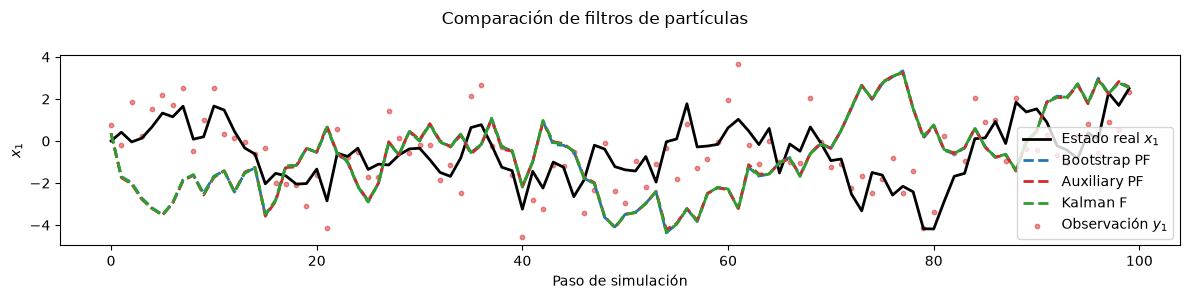

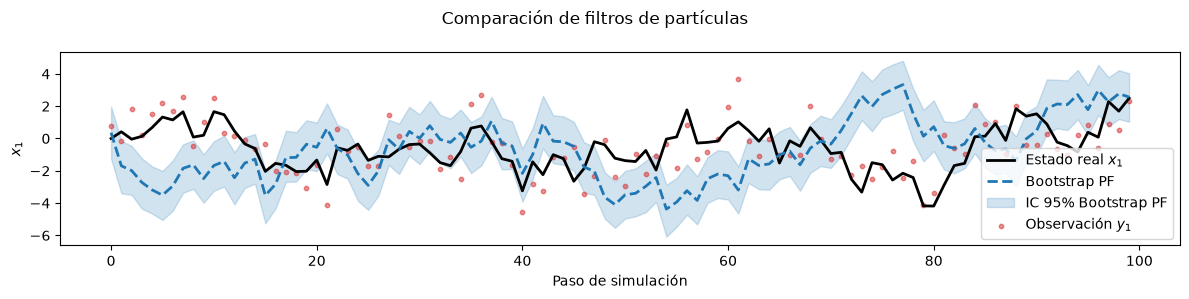

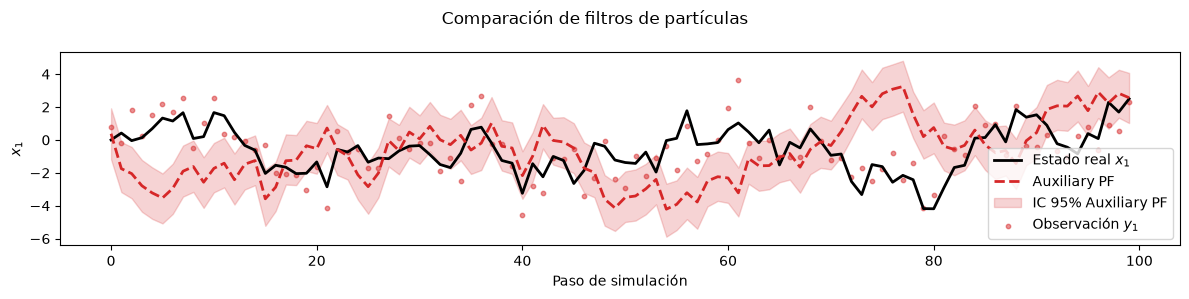

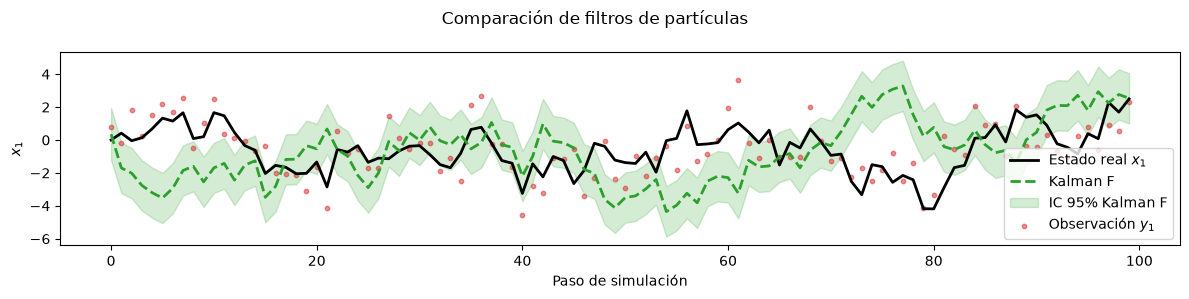

In [39]:
i=7

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"],
    "Kalman F": results_kf[i]["results"]["estimates"]
}

plot_results(x_true, y_obs, estimates)

plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]})

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]})

plot_results(x_true, y_obs, {"Kalman F": results_kf[i]["results"]["estimates"]}, 
            confidence_intervals={"Kalman F": results_kf[i]["results"]["intervals"]})

### Caso 2: Outliers

Aquí la idea del ruido es imitar el hecho de que a veces se producen errores en los procesos de medición.

El ruido sigue una distribución:

$$

w_t = (1 - \epsilon_1)\;\mathcal{N}(v_t; 0, \sigma_1^2)+ \epsilon_2\;\mathcal{N}(v_t;0,\sigma^2_2)
$$
$$
v_t = (1 - \epsilon_2)\;\mathcal{N}(v_t; 0, \sigma_3^2)+ \epsilon_2\;\mathcal{N}(v_t;0,\sigma^2_4)
$$

con $\epsilon_1=0.05$, $\epsilon_2=0.10$, y:

$$
\sigma_1 = \begin{bmatrix}
0.01 
\end{bmatrix}
\;\;
\sigma_2 = \begin{bmatrix}
100.0 
\end{bmatrix}
\;\;
\sigma_3 = \begin{bmatrix}
1.0
\end{bmatrix}
\;\;
\sigma_4 = \begin{bmatrix}
100.0
\end{bmatrix}
$$


Para Kalman, se supone que todos los errores vienen de una gaussiana única con covarianza $\sigma$.

In [12]:
# Matrices del sistema 
A = np.array([[0.95]])
H = np.array([[1.0]])

Q = sigma_1 = np.array([0.01])

R = sigma_3 = np.array([[1.0]])

sigma_2 = np.array([100.0])

sigma_4 = np.array([[100.]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [13]:
from particle_filter.models.noise import OutliersNoise

# Definición de los modelos de transición y observación
noise_transition = OutliersNoise(sigma_1, sigma_2)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = OutliersNoise(sigma_3, sigma_4)
observation = AdditiveObservationModel(h, noise_observation)

In [ ]:
N = 1000
T = 1000
x0 = np.array([0.0])

n_simulations = 1

results = experiment1(T, N, x0, n_simulations, transition, observation, A, H, Q, R, "results_exp2_2")

In [2]:
import pickle

with open("results_exp2.pkl", "rb") as file:
    results = pickle.load(file)

In [3]:
results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]
results_kf = results["Kalman"]

In [4]:
n_simulations = 10

rmse_bpf = np.zeros(n_simulations)
rmse_apf = np.zeros(n_simulations)
rmse_kf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)
loglikelihood_apf = np.zeros(n_simulations)
loglikelihood_kf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)
IC_apf = np.zeros(n_simulations)
IC_kf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
    rmse_apf[i] = RMSE(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"])
    rmse_kf[i] = RMSE(results_kf[i]["x_true"], results_kf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]
    loglikelihood_apf[i] = results_apf[i]["results"]["log_likelihood"]
    loglikelihood_kf[i] = results_kf[i]["results"]["loglikelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])
    IC_apf[i] = Interval_cover(results_apf[i]["x_true"], results_apf[i]["results"]["intervals"])
    IC_kf[i] = Interval_cover(results_kf[i]["x_true"], results_kf[i]["results"]["intervals"])


print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(rmse_apf)} +/- {np.std(rmse_apf)}")
print(f"Filtro de Kalman: {np.mean(rmse_kf)} +/- {np.std(rmse_kf)}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(loglikelihood_apf)} +/- {np.std(loglikelihood_apf)}")
print(f"Filtro de Kalman: {np.mean(loglikelihood_kf)} +/- {np.std(loglikelihood_kf)}\n")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(IC_apf)} +/- {np.std(IC_apf)}")
print(f"Filtro de Kalman: {np.mean(IC_kf)} +/- {np.std(IC_kf)}\n")

RMSE
Bootstrap Particle Filter: 1.5927765661211557 +/- 0.5635243315557952
Auxiliary Particle Filter: 1.4438300253191791 +/- 0.4829519749285311
Filtro de Kalman: 3.4474577651089384 +/- 1.4121770024953586

Log-verosimilitud estimada
Bootstrap Particle Filter: -198.81127335503288 +/- 15.315054701201777
Auxiliary Particle Filter: -196.00511401024568 +/- 15.126991491476716
Filtro de Kalman: -1150.5152457291629 +/- 691.8537235105904

Interval cover
Bootstrap Particle Filter: 92.6 +/- 4.1521078984053394
Auxiliary Particle Filter: 92.9 +/- 4.437341546466758
Filtro de Kalman: 34.9 +/- 16.28158468945821



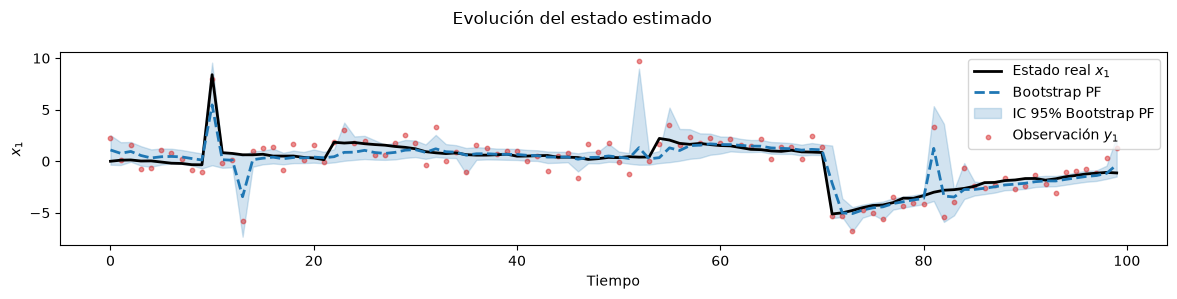

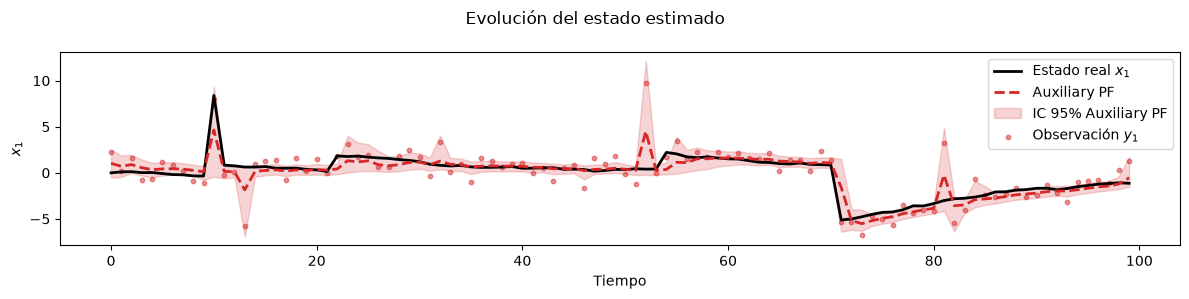

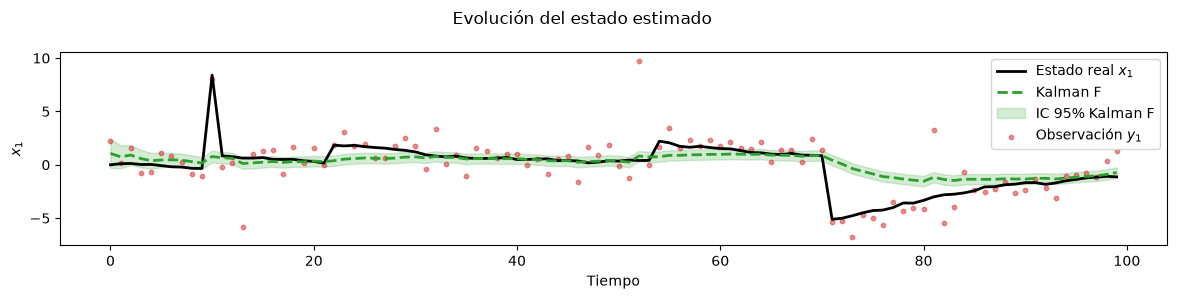

In [10]:
i=8

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"],
    "Kalman F": results_kf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]


plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

plot_results(x_true, y_obs, {"Kalman F": results_kf[i]["results"]["estimates"]}, 
            confidence_intervals={"Kalman F": results_kf[i]["results"]["intervals"]},
            x_title="Tiempo", plot_title="Evolución del estado estimado")

### Caso 3: t-Student

Ahora el ruido sigue una distribución t-Student:

$$
v_t​∼t_ν​(0,\sigma^2)
$$

$$
v_t​∼t_ν​(0,\sigma^2)
$$

con los grados de libertad igual a 3.

El filtro de Kalman supone, de nuevo $R=1$

In [27]:
# Matrices del sistema 
A = np.array([[0.95]])
H = np.array([[1.0]])

Q = np.array([0.01])

R = np.array([[1.0]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [28]:
from particle_filter.models.noise import StudentNoise

# Definición de los modelos de transición y observación
noise_transition = StudentNoise(Q, 3)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = StudentNoise(R, 3)
observation = AdditiveObservationModel(h, noise_observation)

In [29]:
N=1000
T = 100
x0 = np.array([0.0])

n_simulations = 10

results = experiment1(T, N, x0, n_simulations, transition, observation, A, H, Q, R, "results_exp3")

Simulacion 0 finalizada
Simulacion 1 finalizada
Simulacion 2 finalizada
Simulacion 3 finalizada
Simulacion 4 finalizada
Simulacion 5 finalizada
Simulacion 6 finalizada
Simulacion 7 finalizada
Simulacion 8 finalizada
Simulacion 9 finalizada


In [30]:
import pickle 

with open("results_exp3.pkl", "rb") as file:
    results = pickle.load(file)

results_bpf = results["Bootstrap"]
results_apf = results["Bootstrap"]
results_kf = results["Kalman"]

In [31]:
n_simulations = 10

rmse_bpf = np.zeros(n_simulations)
rmse_apf = np.zeros(n_simulations)
rmse_kf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)
loglikelihood_apf = np.zeros(n_simulations)
loglikelihood_kf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)
IC_apf = np.zeros(n_simulations)
IC_kf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
    rmse_apf[i] = RMSE(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"])
    rmse_kf[i] = RMSE(results_kf[i]["x_true"], results_kf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]
    loglikelihood_apf[i] = results_apf[i]["results"]["log_likelihood"]
    loglikelihood_kf[i] = results_kf[i]["results"]["loglikelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])
    IC_apf[i] = Interval_cover(results_apf[i]["x_true"], results_apf[i]["results"]["intervals"])
    IC_kf[i] = Interval_cover(results_kf[i]["x_true"], results_kf[i]["results"]["intervals"])


print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(rmse_apf)} +/- {np.std(rmse_apf)}")
print(f"Filtro de Kalman: {np.mean(rmse_kf)} +/- {np.std(rmse_kf)}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(loglikelihood_apf)} +/- {np.std(loglikelihood_apf)}")
print(f"Filtro de Kalman: {np.mean(loglikelihood_kf)} +/- {np.std(loglikelihood_kf)}\n")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(IC_apf)} +/- {np.std(IC_apf)}")
print(f"Filtro de Kalman: {np.mean(IC_kf)} +/- {np.std(IC_kf)}\n")

RMSE
Bootstrap Particle Filter: 0.3815391136677988 +/- 0.06481038391744286
Auxiliary Particle Filter: 0.3815391136677988 +/- 0.06481038391744286
Filtro de Kalman: 0.40669258653185913 +/- 0.07913537163635304

Log-verosimilitud estimada
Bootstrap Particle Filter: -182.58388115046716 +/- 7.943522820122782
Auxiliary Particle Filter: -182.58388115046716 +/- 7.943522820122782
Filtro de Kalman: -256.60388985979205 +/- 100.52267867543208

Interval cover
Bootstrap Particle Filter: 95.4 +/- 4.340506882842141
Auxiliary Particle Filter: 95.4 +/- 4.340506882842141
Filtro de Kalman: 80.1 +/- 9.438749917229506



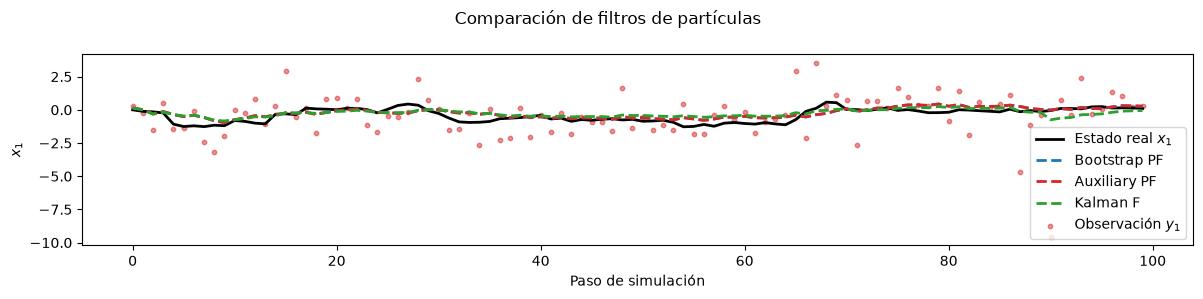

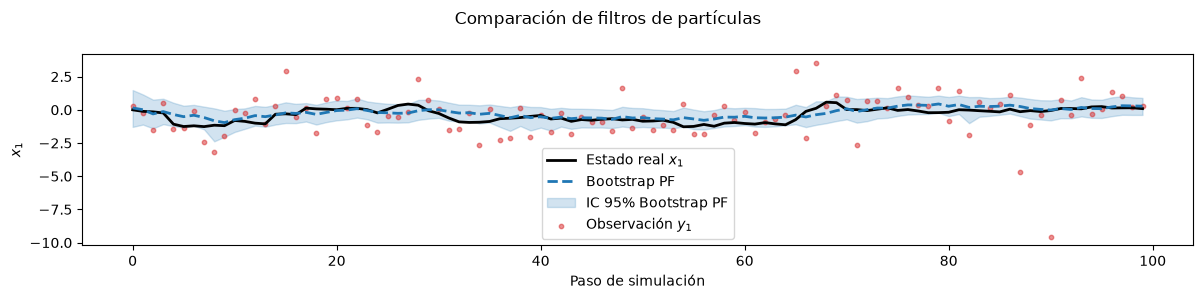

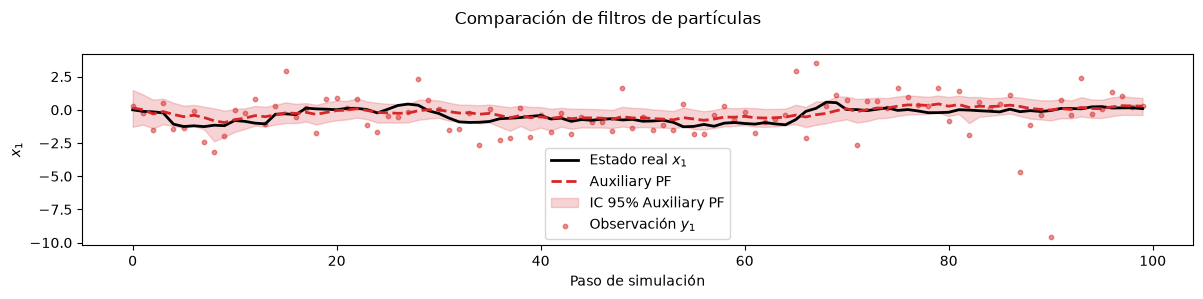

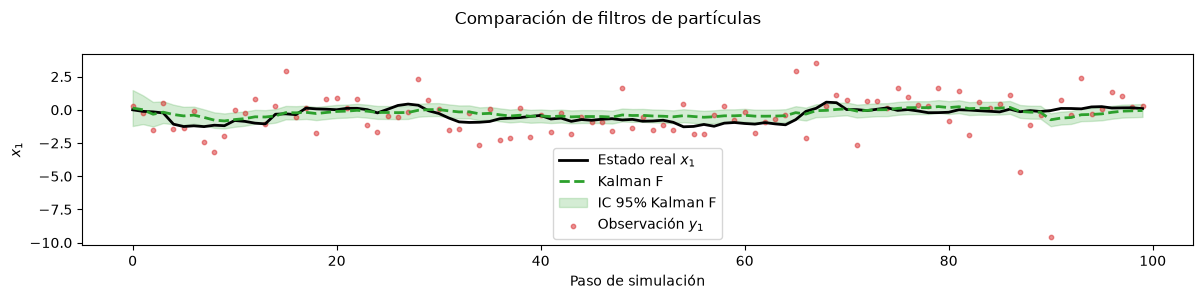

In [34]:
i=2

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"],
    "Kalman F": results_kf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]

plot_results(x_true, y_obs, estimates)

plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]})

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]})

plot_results(x_true, y_obs, {"Kalman F": results_kf[i]["results"]["estimates"]}, 
            confidence_intervals={"Kalman F": results_kf[i]["results"]["intervals"]})